# Week 3 — Monte Carlo Option Pricer
**IEMS 302 consolidation project**

**The goal:** price a European option (a "coupon on the future") by simulating
thousands of possible futures and averaging the payoff — then prove the result
is right by checking it against the exact Black-Scholes formula.

This is **Week 2's simulation trick applied to Week 1's subject.** It also uses
the normal-returns assumption Week 1 questioned, so we use it knowing its limits.

Uses `pricer.py`. Run top to bottom.

## 0. Setup

In [2]:
import sys, pathlib

# pricer.py lives one directory up from this notebook
sys.path.insert(0, str(pathlib.Path.cwd().parent))

import numpy as np
import pricer as pr
from IPython.display import Image, display

S0, r, sigma, T = 180.0, 0.04, 0.28, 1.0   # illustrative GOOGL-like inputs
K = 180                                      # at-the-money strike
rng = np.random.default_rng(7)
results_dir = str(pathlib.Path.cwd().parent / "results")

## 1. Simulate possible futures (Geometric Brownian Motion)

Each future terminal price is
$$S_T = S_0\,\exp\!\Big[\big(r - \tfrac{\sigma^2}{2}\big)T + \sigma\sqrt{T}\,Z\Big],
\quad Z\sim N(0,1).$$
Because $Z$ is normal, $\ln S_T$ is normal, so $S_T$ is **lognormal** — that's
exactly where "returns are normal" enters the model.

In [3]:
paths = pr.simulate_paths(S0, r, sigma, T, 60, 252, rng)
print("simulated", paths.shape[0], "paths;  ending prices range from",
      f"{paths[:,-1].min():.0f} to {paths[:,-1].max():.0f}")

simulated 60 paths;  ending prices range from 84 to 373


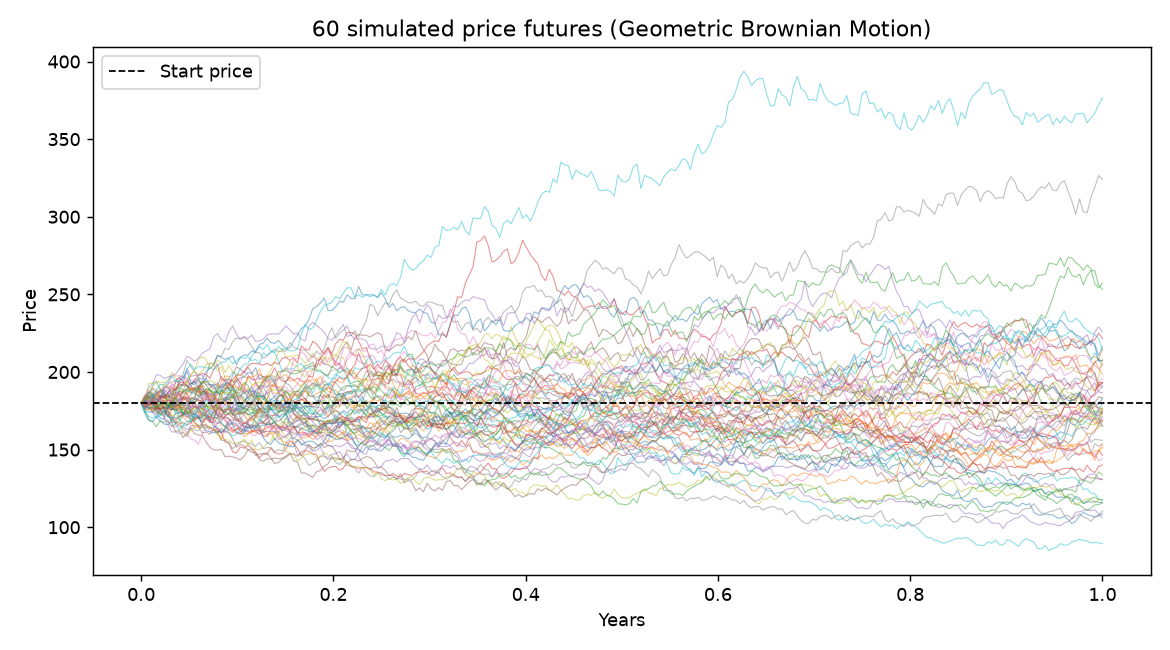

In [4]:
pr._plot_sample_paths(S0, r, sigma, T, np.random.default_rng(1), results_dir)
display(Image(f"{results_dir}/sample_paths.png"))

Some futures soar, some sink — each is one roll of the dice. Pricing an
option means averaging the payoff across *all* of them.

## 2. Price a European call by Monte Carlo
Payoff at expiry: $\max(S_T - K, 0)$. Price = discounted average payoff. The
**95% confidence interval** comes from the Central Limit Theorem — it tells us
how much to trust the estimate.

In [5]:
res = pr.mc_price(S0, K, r, sigma, T, 500_000, "call", rng)
print(f"MC call price = {res['price']:.4f}")
print(f"95% CI        = [{res['ci_low']:.4f}, {res['ci_high']:.4f}]")
print(f"std error     = {res['std_error']:.4f}")

MC call price = 23.3934
95% CI        = [23.2906, 23.4962]
std error     = 0.0524


## 3. Check against Black-Scholes (ground truth)
Black-Scholes gives the *exact* price for a European option. If our simulator is
right, the MC price should land inside the CI around the BS value.

In [6]:
bs = pr.black_scholes(S0, K, r, sigma, T, "call")
print(f"Black-Scholes call = {bs:.4f}")
print(f"Monte Carlo call   = {res['price']:.4f}")
print("BS inside MC 95% CI?", res['ci_low'] <= bs <= res['ci_high'])

Black-Scholes call = 23.3761
Monte Carlo call   = 23.3934
BS inside MC 95% CI? True


## 4. Convergence: error shrinks like $1/\sqrt{n}$
More paths -> tighter estimate, but with diminishing returns: to halve the error
you need **4x** the paths. The fitted slope of $\log(\text{SE})$ vs $\log(n)$
should be about $-0.5$.

fitted slope = -0.496  (theory -0.5)


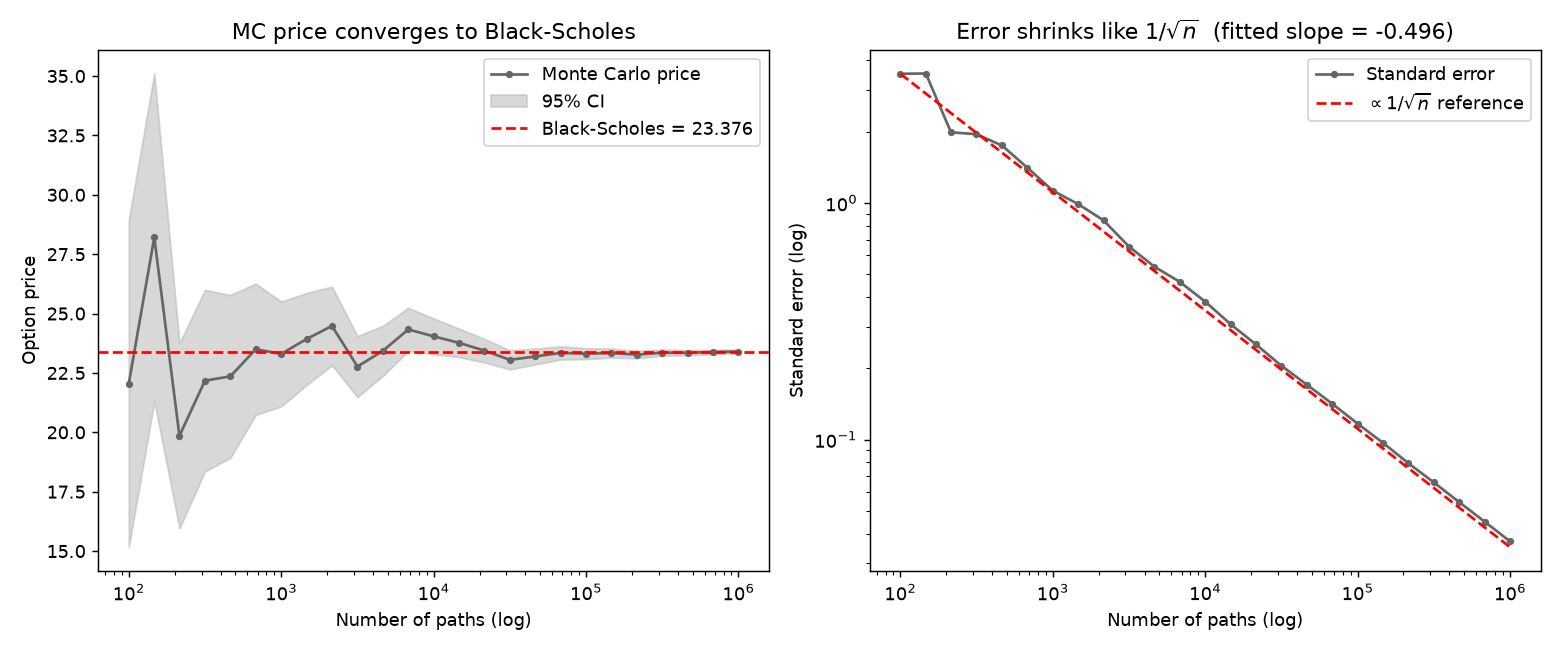

In [7]:
conv = pr.convergence_study(S0, K, r, sigma, T, rng, "call")
print(f"fitted slope = {conv['se_slope']:.3f}  (theory -0.5)")
pr._plot_convergence(conv, results_dir)
display(Image(f"{results_dir}/convergence.png"))

## 5. Validate across many strikes & maturities
Run the full table: deep in/out of the money, short and long maturities, calls
and puts. BS should sit inside the MC confidence interval in every row.

In [8]:
rows = []
for option in ("call","put"):
    for Kx in (160,180,200):
        for Tx in (0.25,1.0):
            b = pr.black_scholes(S0,Kx,r,sigma,Tx,option)
            m = pr.mc_price(S0,Kx,r,sigma,Tx,500_000,option,rng)
            ok = m['ci_low'] <= b <= m['ci_high']
            rows.append((option,Kx,Tx,b,m['price'],ok))
            print(f"{option:>4} K={Kx} T={Tx:.2f}:  BS={b:7.4f}  MC={m['price']:7.4f}  in CI: {ok}")

call K=160 T=0.25:  BS=23.9078  MC=23.9122  in CI: True
call K=160 T=1.00:  BS=34.5634  MC=34.5588  in CI: True
call K=180 T=0.25:  BS=10.9161  MC=10.9180  in CI: True
call K=180 T=1.00:  BS=23.3761  MC=23.3820  in CI: True
call K=200 T=0.25:  BS= 3.8931  MC= 3.8911  in CI: True
call K=200 T=1.00:  BS=15.1971  MC=15.2458  in CI: True
 put K=160 T=0.25:  BS= 2.3158  MC= 2.3289  in CI: True
 put K=160 T=1.00:  BS= 8.2897  MC= 8.2769  in CI: True
 put K=180 T=0.25:  BS= 9.1251  MC= 9.1539  in CI: True
 put K=180 T=1.00:  BS=16.3182  MC=16.2913  in CI: True
 put K=200 T=0.25:  BS=21.9031  MC=21.9148  in CI: True
 put K=200 T=1.00:  BS=27.3550  MC=27.2656  in CI: False


## 6. Where does sigma come from? (Week 1 connection)
The one input you can't read off a screen is **volatility**. Two sources:
- **Historical vol** — from Week 1's daily returns: $\sigma_{ann}=\text{std}(r)\sqrt{252}$.
- **Implied vol** — the sigma that makes BS match an actual market option price;
  it's the market's *forecast* of future risk.

In [9]:
# historical vol straight from a return series (use your Week 1 returns here):
daily = rng.standard_normal(1000)*0.0176          # placeholder ~28% annualised
print("historical vol =", round(pr.historical_volatility(daily),3))

# implied vol: invert BS on a market price (here a price implying 32%)
mkt = pr.black_scholes(S0,K,r,0.32,T,"call")
print("implied vol    =", round(pr.implied_volatility(mkt,S0,K,r,T,"call"),3))

historical vol = 0.282
implied vol    = 0.32


When implied vol > historical, the market expects more turbulence ahead
than the past delivered — often around earnings or big news. **To run this on
live GOOGL data:** `S0, sigma = pr.load_spot_and_vol("GOOGL")`.

## 7. Conclusion
- Monte Carlo prices match Black-Scholes inside the 95% CI for every strike,
  maturity, and option type -> the simulator is validated.
- Error scales as $1/\sqrt{n}$ (slope -0.5) -> the Central Limit Theorem, made
  visible, and a warning that brute-force accuracy is expensive.
- Volatility is the crucial input, and Week 1's historical vol feeds straight in.

**Why it matters:** Week 4 prices options with *no* closed-form formula (Asian /
path-dependent), where Black-Scholes can't help. We can trust MC there precisely
because we validated it here against a known answer — the Week 2 habit again.

**Honest caveat:** GBM assumes normal returns, so it under-prices deep
out-of-the-money options that pay off only in the fat-tailed crashes Week 1
found. That gap *is* much of what implied volatility's "smile" is correcting for.